# Previsão de Ações da Volkswagen com MLOps
## FIAP — Pós Tech em Machine Learning Engineering — Fase 5

**Aluno:** John Robert Marreiro de Oliveira  
**RM:** 365610

### Objetivo
Desenvolver um modelo para prever o preço de fechamento da ação
preferencial da Volkswagen no próximo pregão, utilizando informações
disponíveis até o fechamento do pregão atual.

### Empresa escolhida
Volkswagen AG — ação preferencial VOW3, negociada na Alemanha.
Na fonte de dados Yahoo Finance, utilizaremos o identificador VOW3.DE.
Os preços serão analisados em euros (EUR).

A escolha tem relação com meu interesse pelo setor automotivo
e com minha formação em Engenharia Mecânica.

### Etapas do projeto
1. Coleta e análise dos dados históricos.
2. Preparação dos dados e divisão cronológica.
3. Comparação de modelos com uma previsão de referência.
4. Avaliação dos resultados e registro dos experimentos.
5. Salvamento do modelo e criação de uma API.
6. Publicação com ambiente reproduzível.
7. Monitoramento e documentação.

### Critério de avaliação
Avaliar as previsões em períodos posteriores aos usados no treinamento,
sem utilizar informações futuras. Comparar os modelos com uma referência
simples: prever que o próximo fechamento será igual ao último observado.


In [1]:
# Instala a ferramenta para consultar os dados do Yahoo Finance
%pip install -q yfinance


In [2]:
import yfinance as yf
from IPython.display import display

# Configurações da coleta
TICKER = "VOW3.DE"
DATA_INICIO = "2015-01-01"
DATA_FIM = "2026-11-17"  # Data final exclusiva: busca até 16/11/2026

# Busca os preços diários e os eventos corporativos
dados = yf.download(
    TICKER,
    start=DATA_INICIO,
    end=DATA_FIM,
    interval="1d",
    auto_adjust=False,
    actions=True,
    multi_level_index=False,
    progress=False
)

# Confere se a consulta retornou dados
if dados is None or dados.empty:
    raise ValueError("Nenhum dado recebido. Copie a mensagem exibida para verificarmos.")

dados = dados.sort_index()

print(f"Ação: {TICKER}")
print(f"Quantidade de registros: {len(dados)}")
print(f"Primeira data: {dados.index.min().date()}")
print(f"Última data: {dados.index.max().date()}")
print("\nÚltimos 5 registros:")
display(dados.tail())

Ação: VOW3.DE
Quantidade de registros: 3019
Primeira data: 2015-01-02
Última data: 2026-11-16

Últimos 5 registros:


,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,
2026-11-10,68.480003,68.480003,0.0,71.160004,68.480003,70.860001,0.0,901304
2026-11-11,69.360001,69.360001,0.0,69.639999,68.459999,68.900002,0.0,1003295
2026-11-12,67.720001,67.720001,0.0,70.300003,67.519997,70.180000,0.0,769196
2026-11-13,67.480003,67.480003,0.0,68.059998,67.120003,67.559998,0.0,700418
2026-11-16,67.040001,67.040001,0.0,68.080002,67.040001,67.459999,0.0,615348


In [3]:
import numpy as np

print("VERIFICAÇÃO DOS DADOS")
print("-" * 40)

print(f"Datas repetidas: {dados.index.duplicated().sum()}")
print(f"Datas em ordem: {dados.index.is_monotonic_increasing}")

print("\nValores ausentes por coluna:")
print(dados.isna().sum())

precos = dados[["Open", "High", "Low", "Close"]]

print(f"\nPreços iguais ou menores que zero: {(precos <= 0).sum().sum()}")
print(f"Valores infinitos nos preços: {np.isinf(precos).sum().sum()}")

# A máxima deve ser pelo menos igual à abertura e ao fechamento.
# A mínima deve ser no máximo igual à abertura e ao fechamento.
linhas_inconsistentes = (
    (dados["High"] < dados[["Open", "Close", "Low"]].max(axis=1))
    | (dados["Low"] > dados[["Open", "Close", "High"]].min(axis=1))
)

print(f"Registros com preços inconsistentes: {linhas_inconsistentes.sum()}")
print(f"Registros com volume negativo: {(dados['Volume'] < 0).sum()}")
print(f"Registros com volume zero: {(dados['Volume'] == 0).sum()}")

VERIFICAÇÃO DOS DADOS
----------------------------------------
Datas repetidas: 0
Datas em ordem: True

Valores ausentes por coluna:
Adj Close       0
Close           0
Dividends       0
High            0
Low             0
Open            0
Stock Splits    0
Volume          0
dtype: int64

Preços iguais ou menores que zero: 0
Valores infinitos nos preços: 0
Registros com preços inconsistentes: 0
Registros com volume negativo: 0
Registros com volume zero: 6


In [4]:
# Mostra os registros com volume zero, sem alterar a base
volume_zero = dados.loc[
    dados["Volume"] == 0,
    ["Open", "High", "Low", "Close", "Volume"]
]

print(f"Registros com volume zero: {len(volume_zero)}")
display(volume_zero)


Registros com volume zero: 6


,Open,High,Low,Close,Volume
Date,,,,,
2015-12-25,135.050003,135.050003,135.050003,135.050003,0
2017-06-05,137.550003,137.550003,137.550003,137.550003,0
2017-10-03,137.600006,137.600006,137.600006,137.600006,0
2017-10-31,155.899994,155.899994,155.899994,155.899994,0
2018-05-21,173.100006,173.100006,173.100006,173.100006,0
2026-06-25,76.019997,76.019997,76.019997,76.019997,0


In [5]:
# Compara os dias de volume zero com os registros vizinhos
conferencia = dados[["Close", "Volume"]].copy()

conferencia["Fechamento anterior"] = dados["Close"].shift(1)
conferencia["Fechamento seguinte"] = dados["Close"].shift(-1)

conferencia["Repete o anterior"] = np.isclose(
    conferencia["Close"],
    conferencia["Fechamento anterior"],
    rtol=0,
    atol=0.00001
)

display(conferencia.loc[conferencia["Volume"] == 0])

,Close,Volume,Fechamento anterior,Fechamento seguinte,Repete o anterior
Date,,,,,
2015-12-25,135.050003,0,135.050003,133.149994,True
2017-06-05,137.550003,0,137.550003,134.949997,True
2017-10-03,137.600006,0,137.600006,140.750000,True
2017-10-31,155.899994,0,155.899994,163.350006,True
2018-05-21,173.100006,0,173.100006,176.600006,True
2026-06-25,76.019997,0,76.019997,74.279999,True


In [6]:
%pip install -q exchange_calendars

import exchange_calendars as xcals

calendario = xcals.get_calendar(
    "XETR",
    start=DATA_INICIO,
    end=DATA_FIM
)

checagem = conferencia.loc[conferencia["Volume"] == 0].copy()

checagem["Pregão previsto"] = [
    calendario.is_session(data.strftime("%Y-%m-%d"))
    for data in checagem.index
]

display(checagem[[
    "Close",
    "Volume",
    "Repete o anterior",
    "Pregão previsto"
]])

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ibis-framework 9.5.0 requires toolz<1,>=0.11, but you have toolz 1.2.0 which is incompatible.


,Close,Volume,Repete o anterior,Pregão previsto
Date,,,,
2015-12-25,135.050003,0,True,False
2017-06-05,137.550003,0,True,False
2017-10-03,137.600006,0,True,False
2017-10-31,155.899994,0,True,False
2018-05-21,173.100006,0,True,False
2026-06-25,76.019997,0,True,True


In [7]:
# Preserva a base original
dados_brutos = dados.copy()

# Verifica todas as datas, não apenas as de volume zero
pregao_previsto = [
    calendario.is_session(data.strftime("%Y-%m-%d"))
    for data in dados_brutos.index
]

# Mantém um registro do que foi separado
registros_fora_calendario = dados_brutos.loc[
    [not previsto for previsto in pregao_previsto]
].copy()

# Base de trabalho: somente datas de pregões previstos
dados_tratados = dados_brutos.loc[pregao_previsto].copy()

# Sinaliza possíveis problemas sem excluir esses pregões
dados_tratados["Volume_zero"] = dados_tratados["Volume"].eq(0)

print(f"Registros originais: {len(dados_brutos)}")
print(f"Registros fora do calendário: {len(registros_fora_calendario)}")
print(f"Registros na base de trabalho: {len(dados_tratados)}")

print("\nPregões com volume zero que ainda precisam de investigação:")
display(
    dados_tratados.loc[
        dados_tratados["Volume_zero"],
        ["Open", "High", "Low", "Close", "Volume"]
    ]
)

Registros originais: 3019
Registros fora do calendário: 5
Registros na base de trabalho: 3014

Pregões com volume zero que ainda precisam de investigação:


,Open,High,Low,Close,Volume
Date,,,,,
2026-06-25,76.019997,76.019997,76.019997,76.019997,0


In [8]:
# Consulta novamente um período curto ao redor do registro suspeito
reconsulta = yf.download(
    TICKER,
    start="2026-06-23",
    end="2026-06-30",
    interval="1d",
    auto_adjust=False,
    actions=True,
    multi_level_index=False,
    progress=False
)

if reconsulta is None or reconsulta.empty:
    print("A nova consulta não retornou dados.")
else:
    display(reconsulta[["Open", "High", "Low", "Close", "Volume"]])

,Open,High,Low,Close,Volume
Date,,,,,
2026-06-23,79.019997,79.040001,77.779999,77.919998,1435239
2026-06-24,77.980003,78.099998,76.019997,76.019997,1307957
2026-06-25,76.019997,76.019997,76.019997,76.019997,0
2026-06-26,77.239998,78.239998,74.080002,74.279999,2250935
2026-06-29,74.519997,74.519997,71.360001,71.360001,2020580


In [9]:
# Identifica o registro pendente de validação
registro_suspeito = (
    dados_tratados.index.strftime("%Y-%m-%d") == "2026-06-25"
)

# Registra explicitamente o motivo do tratamento
dados_tratados["Qualidade"] = "Sem problemas nas verificações realizadas"
dados_tratados.loc[registro_suspeito, "Qualidade"] = (
    "Não validado: volume zero e preços iguais ao fechamento anterior"
)

# Preserva a data, mas impede o uso desses valores como observações válidas
colunas_suspeitas = [
    "Open", "High", "Low", "Close", "Adj Close", "Volume"
]

dados_tratados.loc[registro_suspeito, colunas_suspeitas] = np.nan

print(f"Datas mantidas: {len(dados_tratados)}")
print(f"Fechamentos disponíveis: {dados_tratados['Close'].notna().sum()}")
print(f"Fechamentos não validados: {dados_tratados['Close'].isna().sum()}")

display(
    dados_tratados.loc[
        "2026-06-24":"2026-06-26",
        ["Close", "Volume", "Qualidade"]
    ]
)

Datas mantidas: 3014
Fechamentos disponíveis: 3013
Fechamentos não validados: 1


,Close,Volume,Qualidade
Date,,,
2026-06-24,76.019997,1307957.0,Sem problemas nas verificações realizadas
2026-06-25,NaN,NaN,Não validado: volume zero e preços iguais ao f...
2026-06-26,74.279999,2250935.0,Sem problemas nas verificações realizadas


In [10]:
from google.colab import drive
from pathlib import Path

# Conecta seu Google Drive ao Colab
drive.mount("/content/drive")

# Cria a pasta do projeto
PASTA_DADOS = Path(
    "/content/drive/MyDrive/FIAP_Fase5_Volkswagen/dados"
)
PASTA_DADOS.mkdir(parents=True, exist_ok=True)

# Salva os dados originais, a base de trabalho e os registros de auditoria
arquivos = {
    "volkswagen_dados_brutos.csv": dados_brutos,
    "volkswagen_dados_tratados.csv": dados_tratados,
    "registros_fora_calendario.csv": registros_fora_calendario,
    "reconsulta_junho_2026.csv": reconsulta,
}

for nome, tabela in arquivos.items():
    tabela.to_csv(
        PASTA_DADOS / nome,
        index=True,
        index_label="Date"
    )
    print(f"Salvo: {nome}")

print(f"\nPasta: {PASTA_DADOS}")

Mounted at /content/drive
Salvo: volkswagen_dados_brutos.csv
Salvo: volkswagen_dados_tratados.csv
Salvo: registros_fora_calendario.csv
Salvo: reconsulta_junho_2026.csv

Pasta: /content/drive/MyDrive/FIAP_Fase5_Volkswagen/dados


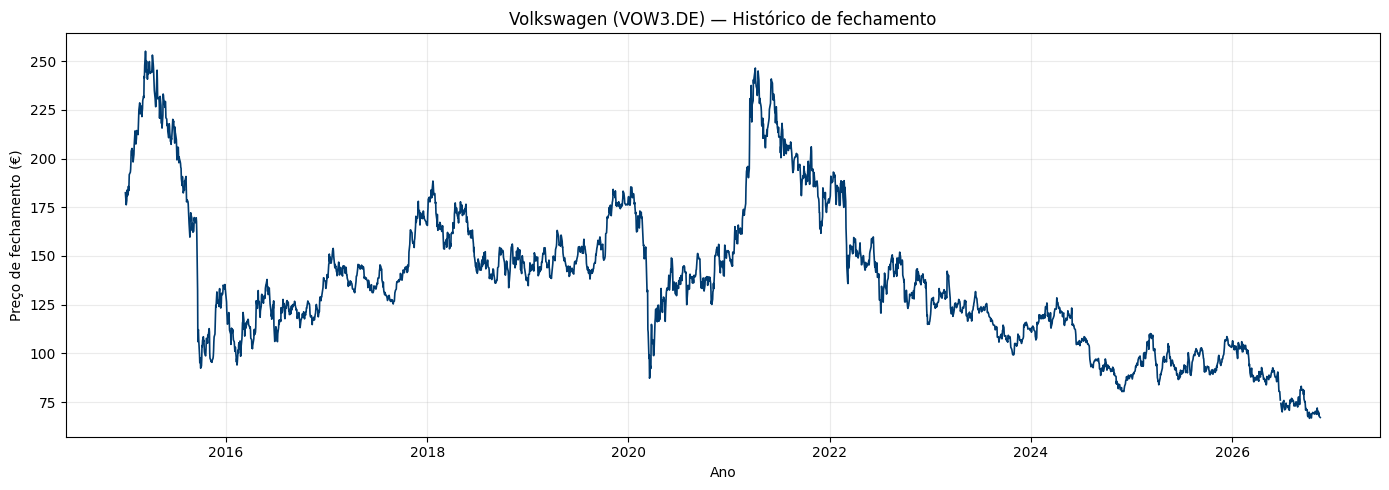

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    dados_tratados.index,
    dados_tratados["Close"],
    color="#003B70",
    linewidth=1.2
)

ax.set_title("Volkswagen (VOW3.DE) — Histórico de fechamento")
ax.set_xlabel("Ano")
ax.set_ylabel("Preço de fechamento (€)")
ax.grid(alpha=0.25)

fig.tight_layout()

# Salva o gráfico no Google Drive
PASTA_FIGURAS = PASTA_DADOS.parent / "figuras"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

fig.savefig(
    PASTA_FIGURAS / "historico_fechamento.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [12]:
import pandas as pd

# Mantém a lacuna do registro não validado.
# Não removemos datas nem preenchemos preços nesta etapa.
serie = dados_tratados["Close"].copy()

treino = serie.loc[serie.index < "2024-01-01"].copy()

validacao = serie.loc[
    (serie.index >= "2024-01-01")
    & (serie.index < "2025-01-01")
].copy()

teste = serie.loc[serie.index >= "2025-01-01"].copy()

partes = {
    "Treino": treino,
    "Validação": validacao,
    "Teste": teste
}

resumo = pd.DataFrame([
    {
        "Parte": nome,
        "Início": parte.index.min().date(),
        "Fim": parte.index.max().date(),
        "Datas": len(parte),
        "Fechamentos disponíveis": parte.notna().sum(),
        "Ausentes": parte.isna().sum()
    }
    for nome, parte in partes.items()
])

# Confere a ordem e a separação dos períodos
assert treino.index.max() < validacao.index.min()
assert validacao.index.max() < teste.index.min()
assert len(treino) + len(validacao) + len(teste) == len(serie)

display(resumo)

resumo.to_csv(PASTA_DADOS / "divisao_temporal.csv", index=False)

,Parte,Início,Fim,Datas,Fechamentos disponíveis,Ausentes
0,Treino,2015-01-02,2023-12-29,2283,2283,0
1,Validação,2024-01-02,2024-12-30,254,254,0
2,Teste,2025-01-02,2026-11-16,477,476,1


In [14]:
# Usa o calendário para garantir que "anterior" seja o pregão anterior.
# Se faltar um pregão na fonte, ele aparecerá como ausente.
datas_pregoes = calendario.sessions_in_range(
    serie.index.min(),
    serie.index.max()
).tz_localize(None)

serie_calendario = serie.reindex(datas_pregoes)

baseline = pd.DataFrame({
    "Real": serie_calendario,
    "Previsao": serie_calendario.shift(1)
})

# Avalia apenas 2024, preservando o fechamento anterior ao início do ano
baseline_validacao = baseline.loc["2024-01-01":"2024-12-31"].copy()

pares_validos = baseline_validacao[["Real", "Previsao"]].notna().all(axis=1)
avaliacao = baseline_validacao.loc[pares_validos].copy()

if avaliacao.empty:
    raise ValueError("Não há pares válidos para avaliar a previsão.")

erro = avaliacao["Real"] - avaliacao["Previsao"]

mae = erro.abs().mean()
rmse = np.sqrt((erro ** 2).mean())
mape = (erro.abs() / avaliacao["Real"]).mean() * 100

print("BASELINE — VALIDAÇÃO 2024")
print(f"Pregões previstos no calendário: {len(baseline_validacao)}")
print(f"Previsões avaliadas: {len(avaliacao)}")
print(f"Pares ausentes: {(~pares_validos).sum()}")
print(f"\nMAE: € {mae:.4f}")
print(f"RMSE: € {rmse:.4f}")
print(f"MAPE: {mape:.2f}%")

display(avaliacao.head())

baseline_validacao.to_csv(
    PASTA_DADOS / "baseline_validacao.csv",
    index_label="Date"
)

BASELINE — VALIDAÇÃO 2024
Pregões previstos no calendário: 254
Previsões avaliadas: 254
Pares ausentes: 0

MAE: € 1.1357
RMSE: € 1.5722
MAPE: 1.09%


,Real,Previsao
2024-01-02,112.879997,111.800003
2024-01-03,110.860001,112.879997
2024-01-04,112.320000,110.860001
2024-01-05,113.260002,112.320000
2024-01-08,114.000000,113.260002


In [15]:
%pip install -q statsmodels

from statsmodels.tsa.arima.model import ARIMA

# Preserva a sequência dos pregões, incluindo eventuais lacunas
treino_arima = serie_calendario.loc[:"2023-12-31"]
validacao_arima = serie_calendario.loc["2024-01-01":"2024-12-31"]

# Ajusta os parâmetros usando apenas o período de treino
arima_inicial = ARIMA(
    treino_arima.to_numpy(),
    order=(1, 1, 0),
    trend="n"
).fit()

if not arima_inicial.mle_retvals.get("converged", False):
    raise RuntimeError("O ajuste não convergiu. Me envie a mensagem exibida.")

# Simula a previsão de um pregão por vez
estado = arima_inicial
previsoes = []

for valor_real in validacao_arima:
    previsao = float(estado.forecast(steps=1)[0])
    previsoes.append(previsao)

    # O valor real só entra depois que a previsão foi feita
    estado = estado.append([valor_real], refit=False)

resultado_arima = pd.DataFrame({
    "Real": validacao_arima,
    "Previsao": previsoes
})

# Compara exatamente as mesmas datas usadas na baseline
comparacao = avaliacao[["Real", "Previsao"]].rename(
    columns={"Previsao": "Baseline"}
).join(resultado_arima["Previsao"].rename("ARIMA"))

assert comparacao.notna().all().all()

metricas = []

for nome in ["Baseline", "ARIMA"]:
    erros = comparacao["Real"] - comparacao[nome]

    metricas.append({
        "Modelo": nome,
        "MAE (€)": erros.abs().mean(),
        "RMSE (€)": np.sqrt((erros ** 2).mean()),
        "MAPE (%)": (erros.abs() / comparacao["Real"]).mean() * 100
    })

tabela_metricas = pd.DataFrame(metricas)

display(tabela_metricas.round(4))

resultado_arima.to_csv(
    PASTA_DADOS / "arima_110_validacao.csv",
    index_label="Date"
)
tabela_metricas.to_csv(
    PASTA_DADOS / "comparacao_inicial_validacao.csv",
    index=False
)

,Modelo,MAE (€),RMSE (€),MAPE (%)
0,Baseline,1.1357,1.5722,1.0864
1,ARIMA,1.1336,1.5737,1.0850


In [16]:
# Mantém os resultados que já obtivemos
resultados_busca = tabela_metricas.copy()
resultados_busca["Modelo"] = resultados_busca["Modelo"].replace({
    "ARIMA": "ARIMA(1,1,0)"
})

configuracoes = [(0, 1, 1), (1, 1, 1), (2, 1, 0)]

for ordem in configuracoes:
    nome = f"ARIMA{ordem}".replace(" ", "")
    print(f"Avaliando {nome}...")

    ajuste = ARIMA(
        treino_arima.to_numpy(),
        order=ordem,
        trend="n"
    ).fit()

    if not ajuste.mle_retvals.get("converged", False):
        print(f"{nome}: ajuste não convergiu; resultado descartado.")
        continue

    estado = ajuste
    previsoes = []

    for valor_real in validacao_arima:
        previsoes.append(float(estado.forecast(steps=1)[0]))
        estado = estado.append([valor_real], refit=False)

    resultado = pd.DataFrame({
        "Real": validacao_arima,
        "Previsao": previsoes
    })

    # Usa exatamente as mesmas datas da baseline
    pares = resultado.loc[avaliacao.index]
    assert np.isfinite(pares.to_numpy()).all()

    erros = pares["Real"] - pares["Previsao"]

    linha = pd.DataFrame([{
        "Modelo": nome,
        "MAE (€)": erros.abs().mean(),
        "RMSE (€)": np.sqrt((erros ** 2).mean()),
        "MAPE (%)": (erros.abs() / pares["Real"]).mean() * 100
    }])

    resultados_busca = pd.concat(
        [resultados_busca, linha],
        ignore_index=True
    )

    identificador = "_".join(map(str, ordem))
    resultado.to_csv(
        PASTA_DADOS / f"arima_{identificador}_validacao.csv",
        index_label="Date"
    )

resultados_busca = resultados_busca.sort_values(
    "MAE (€)"
).reset_index(drop=True)

resultados_busca.to_csv(
    PASTA_DADOS / "comparacao_arima_validacao.csv",
    index=False
)

print("\nCOMPARAÇÃO NA VALIDAÇÃO — menor MAE primeiro")
display(resultados_busca.round(4))

Avaliando ARIMA(0,1,1)...
Avaliando ARIMA(1,1,1)...
Avaliando ARIMA(2,1,0)...

COMPARAÇÃO NA VALIDAÇÃO — menor MAE primeiro


,Modelo,MAE (€),RMSE (€),MAPE (%)
0,"ARIMA(2,1,0)",1.1323,1.5702,1.0845
1,"ARIMA(0,1,1)",1.1334,1.5735,1.0851
2,"ARIMA(1,1,0)",1.1336,1.5737,1.0850
3,"ARIMA(1,1,1)",1.1348,1.5739,1.0873
4,Baseline,1.1357,1.5722,1.0864


In [17]:
ORDEM_ESCOLHIDA = (2, 1, 0)

# Treinamento final: todos os dados anteriores ao teste
historico_pre_teste = serie_calendario.loc[:"2024-12-31"]
serie_teste = serie_calendario.loc["2025-01-01":]

modelo_pre_teste = ARIMA(
    historico_pre_teste.to_numpy(),
    order=ORDEM_ESCOLHIDA,
    trend="n"
).fit()

if not modelo_pre_teste.mle_retvals.get("converged", False):
    raise RuntimeError("O ajuste não convergiu. Me envie a mensagem.")

estado_teste = modelo_pre_teste
previsoes_teste = []

for valor_real in serie_teste:
    previsoes_teste.append(float(estado_teste.forecast(steps=1)[0]))

    # O statsmodels aceita NaN como observação ausente.
    # O preço suspeito não é inventado nem usado como valor observado.
    estado_teste = estado_teste.append([valor_real], refit=False)

resultado_teste = pd.DataFrame({
    "Real": serie_teste,
    "Baseline": serie_calendario.shift(1).reindex(serie_teste.index),
    "ARIMA": previsoes_teste
})

# Compara os dois métodos exatamente nos mesmos pregões válidos.
# A lacuna também impede avaliar a baseline no pregão seguinte.
mascara_valida = np.isfinite(resultado_teste).all(axis=1)
teste_comparavel = resultado_teste.loc[mascara_valida].copy()

if teste_comparavel.empty:
    raise ValueError("Não há pares válidos para avaliação.")

metricas_teste = []

for nome in ["Baseline", "ARIMA"]:
    erros = teste_comparavel["Real"] - teste_comparavel[nome]

    metricas_teste.append({
        "Modelo": nome,
        "MAE (€)": erros.abs().mean(),
        "RMSE (€)": np.sqrt((erros ** 2).mean()),
        "MAPE (%)": (
            erros.abs() / teste_comparavel["Real"]
        ).mean() * 100
    })

tabela_teste = pd.DataFrame(metricas_teste)

print(f"Pregões no período de teste: {len(resultado_teste)}")
print(f"Pregões comparados: {len(teste_comparavel)}")
print(f"Pregões excluídos da comparação: {(~mascara_valida).sum()}")

display(tabela_teste.round(4))

resultado_teste.to_csv(
    PASTA_DADOS / "previsoes_teste.csv",
    index_label="Date"
)
tabela_teste.to_csv(
    PASTA_DADOS / "metricas_teste.csv",
    index=False
)

Pregões no período de teste: 477
Pregões comparados: 475
Pregões excluídos da comparação: 2


,Modelo,MAE (€),RMSE (€),MAPE (%)
0,Baseline,1.2695,1.6941,1.4127
1,ARIMA,1.2723,1.7006,1.4147


### Resultados e decisão de modelagem

A configuração ARIMA(2,1,0) foi selecionada pelo menor MAE na
validação de 2024, entre quatro configurações avaliadas.
Sua melhoria sobre a baseline foi de aproximadamente 0,30%.

Após a seleção, seus parâmetros foram ajustados com os dados
até dezembro de 2024. A avaliação de teste simulou previsões
de um pregão à frente, incorporando cada observação somente
após gerar a previsão correspondente, sem reajustar os parâmetros.

No teste, de janeiro de 2025 a novembro de 2026:

| Modelo | MAE (€) | RMSE (€) | MAPE (%) |
|---|---:|---:|---:|
| Baseline: último fechamento | 1,2695 | 1,6941 | 1,4127 |
| ARIMA(2,1,0) | 1,2723 | 1,7006 | 1,4147 |

Foram comparados 475 dos 477 pregões. O registro de 25/06/2026
não foi validado, e o pregão seguinte não tinha um fechamento
anterior válido para a baseline. Ambos foram excluídos da
comparação, garantindo as mesmas datas para os dois métodos.

A vantagem observada na validação não se confirmou no teste.
Não foi demonstrada superioridade preditiva do ARIMA sobre
a baseline, nem avaliada a rentabilidade de uma estratégia financeira.

O ARIMA será disponibilizado como modelo experimental para
demonstrar o ciclo de MLOps, mantendo a baseline como referência
no monitoramento. A configuração não será reajustada com base
nos resultados deste teste.

In [18]:
%pip install -q mlflow

import mlflow

print(f"Versão do MLflow: {mlflow.__version__}")
print("MLflow importado com sucesso.")

Versão do MLflow: 3.18.0
MLflow importado com sucesso.


In [19]:
from pathlib import Path
import shutil
import sqlite3

PASTA_MLFLOW = PASTA_DADOS.parent / "mlflow"
PASTA_ARTEFATOS = PASTA_MLFLOW / "artefatos"
PASTA_ARTEFATOS.mkdir(parents=True, exist_ok=True)

BANCO_LOCAL = Path("/content/fiap_volkswagen_mlflow.db")
BANCO_DRIVE = PASTA_MLFLOW / "mlflow.db"

# Recupera o histórico ao iniciar uma nova sessão
if not BANCO_LOCAL.exists() and BANCO_DRIVE.exists():
    shutil.copy2(BANCO_DRIVE, BANCO_LOCAL)

mlflow.set_tracking_uri(f"sqlite:///{BANCO_LOCAL}")

NOME_EXPERIMENTO = "FIAP_Fase5_Volkswagen"

experimento = mlflow.get_experiment_by_name(NOME_EXPERIMENTO)

if experimento is None:
    mlflow.create_experiment(
        NOME_EXPERIMENTO,
        artifact_location=PASTA_ARTEFATOS.as_uri()
    )

experimento = mlflow.set_experiment(NOME_EXPERIMENTO)

# Cria uma cópia consistente do banco antes de enviá-la ao Drive
def salvar_historico_mlflow():
    copia_local = Path("/content/fiap_mlflow_backup.db")

    with sqlite3.connect(str(BANCO_LOCAL)) as origem:
        with sqlite3.connect(str(copia_local)) as destino:
            origem.backup(destino)

    shutil.copy2(copia_local, BANCO_DRIVE)

salvar_historico_mlflow()

print(f"Experimento: {experimento.name}")
print(f"ID: {experimento.experiment_id}")
print("Cópia do histórico salva no Google Drive.")

2026/11/17 19:10:15 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/17 19:10:15 INFO mlflow.store.db.utils: Updating database tables


Experimento: FIAP_Fase5_Volkswagen
ID: 1
Cópia do histórico salva no Google Drive.


In [20]:
import hashlib

# Identifica exatamente a versão da base utilizada
arquivo_base = PASTA_DADOS / "volkswagen_dados_tratados.csv"
hash_base = hashlib.sha256(arquivo_base.read_bytes()).hexdigest()

arquivos_validacao = {
    "Baseline": "baseline_validacao.csv",
    "ARIMA(1,1,0)": "arima_110_validacao.csv",
    "ARIMA(0,1,1)": "arima_0_1_1_validacao.csv",
    "ARIMA(1,1,1)": "arima_1_1_1_validacao.csv",
    "ARIMA(2,1,0)": "arima_2_1_0_validacao.csv"
}

etapas = [
    ("validacao", resultados_busca, "2023-12-29"),
    ("teste", tabela_teste, "2024-12-30")
]

registros_mlflow = []

for etapa, tabela, fim_treino in etapas:
    for _, linha in tabela.iterrows():
        modelo = linha["Modelo"]

        if etapa == "teste" and modelo == "ARIMA":
            modelo = "ARIMA(2,1,0)"

        if etapa == "validacao":
            arquivo_previsoes = arquivos_validacao[modelo]
        else:
            arquivo_previsoes = "previsoes_teste.csv"

        with mlflow.start_run(run_name=f"{etapa}_{modelo}") as run:
            mlflow.set_tags({
                "registro": "retrospectivo",
                "etapa": etapa,
                "modelo": modelo,
                "finalidade": "Projeto acadêmico FIAP",
                "selecao": "Menor MAE na validação"
            })

            mlflow.log_params({
                "ticker": TICKER,
                "alvo": "Close",
                "moeda": "EUR",
                "horizonte": "1 pregão",
                "fim_treino": fim_treino,
                "base_sha256": hash_base,
                "regra_baseline": "Fechamento do pregão anterior",
                "ordem_arima": (
                    modelo.replace("ARIMA", "")
                    if modelo.startswith("ARIMA")
                    else "nao_aplicavel"
                ),
                "reajuste_diario_parametros": False
            })

            mlflow.log_metrics({
                "mae_eur": float(linha["MAE (€)"]),
                "rmse_eur": float(linha["RMSE (€)"]),
                "mape_percentual": float(linha["MAPE (%)"])
            })

            mlflow.log_artifact(
                str(PASTA_DADOS / arquivo_previsoes),
                artifact_path="previsoes"
            )

            registros_mlflow.append({
                "Etapa": etapa,
                "Modelo": modelo,
                "Run ID": run.info.run_id
            })

# Guarda os identificadores e atualiza a cópia do banco no Drive
pd.DataFrame(registros_mlflow).to_csv(
    PASTA_MLFLOW / "registros_experimentos.csv",
    index=False
)

salvar_historico_mlflow()

print(f"Registros criados nesta execução: {len(registros_mlflow)}")
print("Histórico atualizado no Google Drive.")
display(pd.DataFrame(registros_mlflow))

Registros criados nesta execução: 7
Histórico atualizado no Google Drive.


,Etapa,Modelo,Run ID
0,validacao,"ARIMA(2,1,0)",3a7e7fd7ec884a789d12fdb540e0df4c
1,validacao,"ARIMA(0,1,1)",d7c304704ee84e5a9e5f1e13b86ee32a
2,validacao,"ARIMA(1,1,0)",d7c317b0d08f4dbc8a6a216aff4f58f6
3,validacao,"ARIMA(1,1,1)",4ab8e94324d6489abc6dbfec8ee7d827
4,validacao,Baseline,ccd56edb16734ac4ac9b363c02b5f679
5,teste,Baseline,25dc010342184aeba2c529ddb4458cee
6,teste,"ARIMA(2,1,0)",6c489496181e4713854444a140f5df19


In [21]:
from statsmodels.tsa.arima.model import ARIMAResults
import statsmodels
import json
import platform

PASTA_MODELOS = PASTA_DADOS.parent / "modelos"
PASTA_MODELOS.mkdir(parents=True, exist_ok=True)

# Salva o estado anterior à avaliação e o atualizado após o teste
modelo_pre_teste.save(
    str(PASTA_MODELOS / "arima_210_pre_teste.pkl")
)

arquivo_modelo = PASTA_MODELOS / "arima_210_atualizado.pkl"
estado_teste.save(str(arquivo_modelo))

# Carrega o arquivo e verifica se a previsão foi preservada
modelo_carregado = ARIMAResults.load(str(arquivo_modelo))

previsao_original = float(estado_teste.forecast(steps=1)[0])
previsao_carregada = float(modelo_carregado.forecast(steps=1)[0])

np.testing.assert_allclose(
    previsao_original,
    previsao_carregada,
    rtol=0,
    atol=1e-10
)

# Documenta o modelo e o ambiente usado
metadados_modelo = {
    "modelo": "ARIMA",
    "ordem": list(ORDEM_ESCOLHIDA),
    "ticker": TICKER,
    "alvo": "Close",
    "moeda": "EUR",
    "horizonte": "1 pregao",
    "parametros_ajustados_ate": str(historico_pre_teste.index.max().date()),
    "observacoes_incorporadas_ate": str(serie_teste.index.max().date()),
    "base_sha256": hash_base,
    "modelo_sha256": hashlib.sha256(arquivo_modelo.read_bytes()).hexdigest(),
    "python": platform.python_version(),
    "statsmodels": statsmodels.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "status": "Experimental; nao superou a baseline no teste"
}

with open(
    PASTA_MODELOS / "metadados_modelo.json",
    "w",
    encoding="utf-8"
) as arquivo:
    json.dump(metadados_modelo, arquivo, indent=2, ensure_ascii=False)

print("Modelos e metadados salvos no Google Drive.")
print("Verificação aprovada: previsão preservada após carregar.")
print(f"Previsão original: € {previsao_original:.4f}")
print(f"Previsão carregada: € {previsao_carregada:.4f}")

Modelos e metadados salvos no Google Drive.
Verificação aprovada: previsão preservada após carregar.
Previsão original: € 67.0109
Previsão carregada: € 67.0109


In [22]:
# Localiza o registro da avaliação do ARIMA no teste
run_teste_arima = next(
    registro["Run ID"]
    for registro in registros_mlflow
    if registro["Etapa"] == "teste"
    and registro["Modelo"] == "ARIMA(2,1,0)"
)

with mlflow.start_run(run_name="pacote_modelo_arima_210") as run:
    mlflow.set_tags({
        "etapa": "preparacao_api",
        "status_modelo": "experimental",
        "run_avaliacao_teste": run_teste_arima,
        "resultado": "Nao superou a baseline no teste"
    })

    mlflow.log_params({
        "ticker": TICKER,
        "ordem": str(ORDEM_ESCOLHIDA),
        "parametros_ajustados_ate":
            metadados_modelo["parametros_ajustados_ate"],
        "observacoes_incorporadas_ate":
            metadados_modelo["observacoes_incorporadas_ate"],
        "modelo_sha256": metadados_modelo["modelo_sha256"],
        "base_sha256": hash_base,
        "statsmodels": statsmodels.__version__,
        "python": platform.python_version()
    })

    mlflow.log_metric(
        "diferenca_apos_carregar",
        abs(previsao_original - previsao_carregada)
    )

    # Anexa os dois modelos e o arquivo de metadados
    mlflow.log_artifacts(
        str(PASTA_MODELOS),
        artifact_path="modelos"
    )

    RUN_PACOTE_MODELO = run.info.run_id

# Guarda a ligação entre o pacote e sua avaliação
with open(
    PASTA_MLFLOW / "referencias_modelo.json",
    "w",
    encoding="utf-8"
) as arquivo:
    json.dump({
        "run_pacote_modelo": RUN_PACOTE_MODELO,
        "run_avaliacao_teste": run_teste_arima
    }, arquivo, indent=2)

salvar_historico_mlflow()

print("Arquivos do modelo vinculados ao MLflow.")
print(f"Run do pacote: {RUN_PACOTE_MODELO}")
print("Histórico atualizado no Google Drive.")

Arquivos do modelo vinculados ao MLflow.
Run do pacote: f90300d803cc40b284d2c7627a879e7c
Histórico atualizado no Google Drive.


In [24]:
import sys
import subprocess
import scipy
import patsy

AMBIENTE_API = Path("/content/fiap_api_venv")
PYTHON_API = AMBIENTE_API / "bin" / "python"

# Cria o ambiente isolado
subprocess.run(
    [sys.executable, "-m", "venv", str(AMBIENTE_API)],
    check=True
)

# Preserva as versões das bibliotecas que participaram do modelo
dependencias_api = [
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"scipy=={scipy.__version__}",
    f"statsmodels=={statsmodels.__version__}",
    f"patsy=={patsy.__version__}",
    "fastapi",
    "uvicorn",
    "httpx",
    "exchange_calendars"
]

instalacao = subprocess.run(
    [
        str(PYTHON_API), "-m", "pip", "install",
        *dependencias_api
    ],
    capture_output=True,
    text=True
)

if instalacao.returncode != 0:
    print(instalacao.stdout[-4000:])
    print(instalacao.stderr[-4000:])
    raise RuntimeError("A instalação falhou. Me envie a mensagem acima.")

# Confere se as dependências são compatíveis entre si
checagem = subprocess.run(
    [str(PYTHON_API), "-m", "pip", "check"],
    capture_output=True,
    text=True
)

print(checagem.stdout)
print(checagem.stderr)

if checagem.returncode != 0:
    raise RuntimeError("Há conflitos no ambiente da API.")

# Salva as versões instaladas para reproduzir o ambiente
PASTA_API = PASTA_DADOS.parent / "api"
PASTA_API.mkdir(parents=True, exist_ok=True)

versoes = subprocess.check_output(
    [str(PYTHON_API), "-m", "pip", "freeze"],
    text=True
)

(PASTA_API / "requirements.txt").write_text(
    versoes,
    encoding="utf-8"
)

print("Ambiente da API criado e dependências verificadas.")
print("requirements.txt salvo no Google Drive.")

CalledProcessError: Command '['/usr/bin/python3', '-m', 'venv', '/content/fiap_api_venv']' returned non-zero exit status 1.

In [25]:
import sys
import subprocess

diagnostico = subprocess.run(
    [sys.executable, "-m", "venv", "/content/fiap_api_venv"],
    capture_output=True,
    text=True
)

print("Python:", sys.version)
print("\nSAÍDA:")
print(diagnostico.stdout or "(sem mensagem)")
print("\nERRO:")
print(diagnostico.stderr or "(sem mensagem)")
print("\nCódigo de retorno:", diagnostico.returncode)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]

SAÍDA:
(sem mensagem)

ERRO:
Error: Command '['/content/fiap_api_venv/bin/python3', '-m', 'ensurepip', '--upgrade', '--default-pip']' returned non-zero exit status 1.


Código de retorno: 1


In [26]:
%pip install -q virtualenv

import sys
import subprocess
from pathlib import Path

AMBIENTE_API = Path("/content/fiap_api_venv")
PYTHON_API = AMBIENTE_API / "bin" / "python"

criacao = subprocess.run(
    [
        sys.executable, "-m", "virtualenv",
        "--python", sys.executable,
        str(AMBIENTE_API)
    ],
    capture_output=True,
    text=True
)

print(criacao.stdout)
print(criacao.stderr)

if criacao.returncode != 0:
    raise RuntimeError("Falha ao criar o ambiente. Envie a mensagem acima.")

verificacao = subprocess.run(
    [str(PYTHON_API), "-m", "pip", "--version"],
    capture_output=True,
    text=True
)

print(verificacao.stdout)
print(verificacao.stderr)

if verificacao.returncode != 0:
    raise RuntimeError("O pip ainda não funcionou. Envie a mensagem acima.")

print("Ambiente virtual criado e pip funcionando.")

created virtual environment CPython3.13.18.final.0-64-x86_64 in 565ms
  creator CPython3Posix(dest=/content/fiap_api_venv, clear=False, no_vcs_ignore=False, venv_redirect=None, global=False)
  seeder FromAppData(download=False, pip=bundle, via=copy, app_data_dir=/root/.cache/virtualenv)
    added seed packages: pip==26.3
  activators BashActivator,CShellActivator,FishActivator,NushellActivator,PowerShellActivator,PythonActivator,XonshActivator


pip 26.3 from /content/fiap_api_venv/lib/python3.13/site-packages/pip (python 3.13)


Ambiente virtual criado e pip funcionando.


In [27]:
import scipy
import patsy

dependencias_api = [
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"scipy=={scipy.__version__}",
    f"statsmodels=={statsmodels.__version__}",
    f"patsy=={patsy.__version__}",
    "fastapi",
    "uvicorn",
    "httpx",
    "exchange_calendars"
]

print("Instalando as dependências da API...")

instalacao = subprocess.run(
    [str(PYTHON_API), "-m", "pip", "install", *dependencias_api],
    capture_output=True,
    text=True
)

if instalacao.returncode != 0:
    print(instalacao.stdout[-6000:])
    print(instalacao.stderr[-6000:])
    raise RuntimeError("A instalação falhou. Envie a mensagem acima.")

# Verifica conflitos entre as dependências instaladas
checagem = subprocess.run(
    [str(PYTHON_API), "-m", "pip", "check"],
    capture_output=True,
    text=True
)

print(checagem.stdout)
print(checagem.stderr)

if checagem.returncode != 0:
    raise RuntimeError("Foram encontrados conflitos no ambiente.")

# Salva as versões exatas para reproduzir o ambiente
PASTA_API = PASTA_DADOS.parent / "api"
PASTA_API.mkdir(parents=True, exist_ok=True)

versoes = subprocess.check_output(
    [str(PYTHON_API), "-m", "pip", "freeze"],
    text=True
)

(PASTA_API / "requirements.txt").write_text(
    versoes,
    encoding="utf-8"
)

print("Dependências instaladas e verificadas.")
print("requirements.txt salvo no Google Drive.")

Instalando as dependências da API...
No broken requirements found.


Dependências instaladas e verificadas.
requirements.txt salvo no Google Drive.


In [28]:
import textwrap

# Organiza os arquivos que acompanharão a API
PASTA_MODELOS_API = PASTA_API / "modelos"
PASTA_MODELOS_API.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    PASTA_MODELOS / "arima_210_atualizado.pkl",
    PASTA_MODELOS_API / "arima_210_atualizado.pkl"
)

metadados_api = metadados_modelo.copy()
metadados_api["previsao_referencia"] = previsao_original

(PASTA_MODELOS_API / "metadados_modelo.json").write_text(
    json.dumps(metadados_api, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# Este programa será executado pelo Python do ambiente isolado
codigo_verificacao = textwrap.dedent("""
    from pathlib import Path
    import hashlib
    import json
    import sys
    import numpy as np
    from statsmodels.tsa.arima.model import ARIMAResults

    pasta = Path(__file__).resolve().parent / "modelos"
    arquivo = pasta / "arima_210_atualizado.pkl"
    metadados = json.loads(
        (pasta / "metadados_modelo.json").read_text(encoding="utf-8")
    )

    hash_atual = hashlib.sha256(arquivo.read_bytes()).hexdigest()
    if hash_atual != metadados["modelo_sha256"]:
        raise RuntimeError("O arquivo do modelo difere da versão registrada.")

    modelo = ARIMAResults.load(str(arquivo))
    previsao = float(modelo.forecast(steps=1)[0])

    np.testing.assert_allclose(
        previsao,
        metadados["previsao_referencia"],
        rtol=0,
        atol=1e-8
    )

    print(f"Python utilizado: {sys.executable}")
    print("Integridade do arquivo: aprovada.")
    print(f"Previsão no ambiente isolado: € {previsao:.4f}")
    print("Modelo validado no ambiente da API.")
""")

arquivo_verificacao = PASTA_API / "verificar_modelo.py"
arquivo_verificacao.write_text(codigo_verificacao, encoding="utf-8")

resultado = subprocess.run(
    [str(PYTHON_API), str(arquivo_verificacao)],
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

if resultado.returncode != 0:
    raise RuntimeError("A verificação falhou. Envie a mensagem acima.")

Python utilizado: /content/fiap_api_venv/bin/python
Integridade do arquivo: aprovada.
Previsão no ambiente isolado: € 67.0109
Modelo validado no ambiente da API.




In [29]:
codigo_api = textwrap.dedent("""
    from contextlib import asynccontextmanager
    from pathlib import Path
    import hashlib
    import json
    import numpy as np

    from fastapi import FastAPI
    from statsmodels.tsa.arima.model import ARIMAResults

    PASTA_MODELOS = Path(__file__).resolve().parent / "modelos"

    @asynccontextmanager
    async def lifespan(app: FastAPI):
        arquivo = PASTA_MODELOS / "arima_210_atualizado.pkl"
        metadados = json.loads(
            (PASTA_MODELOS / "metadados_modelo.json").read_text(
                encoding="utf-8"
            )
        )

        hash_atual = hashlib.sha256(arquivo.read_bytes()).hexdigest()
        if hash_atual != metadados["modelo_sha256"]:
            raise RuntimeError("Integridade do modelo não confirmada.")

        modelo = ARIMAResults.load(str(arquivo))
        previsao = float(modelo.forecast(steps=1)[0])

        np.testing.assert_allclose(
            previsao,
            metadados["previsao_referencia"],
            rtol=0,
            atol=1e-8
        )

        app.state.modelo = modelo
        app.state.metadados = metadados
        yield
        app.state.modelo = None

    app = FastAPI(
        title="Volkswagen — API de previsão",
        description="Projeto acadêmico FIAP: previsão experimental com ARIMA.",
        version="0.1.0",
        lifespan=lifespan
    )

    @app.get("/health")
    def health():
        return {
            "status": "ok",
            "modelo_carregado": app.state.modelo is not None,
            "dados_ate": app.state.metadados["observacoes_incorporadas_ate"]
        }

    @app.get("/modelo")
    def informacoes_modelo():
        meta = app.state.metadados
        return {
            "modelo": meta["modelo"],
            "ordem": meta["ordem"],
            "ticker": meta["ticker"],
            "moeda": meta["moeda"],
            "horizonte": meta["horizonte"],
            "parametros_ajustados_ate": meta["parametros_ajustados_ate"],
            "dados_ate": meta["observacoes_incorporadas_ate"],
            "versao_modelo": meta["modelo_sha256"],
            "status": meta["status"]
        }
""")

(PASTA_API / "main.py").write_text(codigo_api, encoding="utf-8")

# Testa a inicialização e as duas rotas no ambiente isolado
codigo_teste = textwrap.dedent("""
    from fastapi.testclient import TestClient
    from main import app

    with TestClient(app) as cliente:
        saude = cliente.get("/health")
        assert saude.status_code == 200
        assert saude.json()["modelo_carregado"] is True

        modelo = cliente.get("/modelo")
        assert modelo.status_code == 200
        assert modelo.json()["ticker"] == "VOW3.DE"
        assert modelo.json()["ordem"] == [2, 1, 0]

        print("GET /health:", saude.json())
        print("GET /modelo:", modelo.json())
        print("Inicialização e rotas verificadas com sucesso.")
""")

(PASTA_API / "test_inicializacao.py").write_text(
    codigo_teste,
    encoding="utf-8"
)

resultado = subprocess.run(
    [str(PYTHON_API), str(PASTA_API / "test_inicializacao.py")],
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

if resultado.returncode != 0:
    raise RuntimeError("O teste falhou. Envie a mensagem acima.")

GET /health: {'status': 'ok', 'modelo_carregado': True, 'dados_ate': '2026-11-16'}
GET /modelo: {'modelo': 'ARIMA', 'ordem': [2, 1, 0], 'ticker': 'VOW3.DE', 'moeda': 'EUR', 'horizonte': '1 pregao', 'parametros_ajustados_ate': '2024-12-30', 'dados_ate': '2026-11-16', 'versao_modelo': '82be1c3099e4e7e35bf350386ddee5b767799e40108366e9d07adf9942f2640f', 'status': 'Experimental; nao superou a baseline no teste'}
Inicialização e rotas verificadas com sucesso.

/content/fiap_api_venv/lib/python3.13/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa



In [30]:
codigo_previsao = textwrap.dedent("""
    from copy import deepcopy
    from datetime import date, timedelta
    from typing import Literal
    import numpy as np
    import pandas as pd
    import exchange_calendars as xcals

    from fastapi import APIRouter, HTTPException, Request
    from pydantic import BaseModel, ConfigDict, Field

    router = APIRouter()

    class Observacao(BaseModel):
        model_config = ConfigDict(extra="forbid")
        data: date
        fechamento: float = Field(
            gt=0, allow_inf_nan=False, strict=True
        )

    class PedidoPrevisao(BaseModel):
        model_config = ConfigDict(extra="forbid")
        ticker: Literal["VOW3.DE"]
        observacoes: list[Observacao] = Field(
            default_factory=list, max_length=366
        )

    @router.post("/prever")
    def prever(pedido: PedidoPrevisao, request: Request):
        meta = request.app.state.metadados
        data_base = date.fromisoformat(
            meta["observacoes_incorporadas_ate"]
        )
        agora = pd.Timestamp.now(tz="UTC")
        hoje = agora.tz_convert("Europe/Berlin").date()

        datas = [item.data for item in pedido.observacoes]

        if any(d <= data_base or d > hoje for d in datas):
            raise HTTPException(
                status_code=422,
                detail="Envie somente datas posteriores à base e até hoje."
            )

        calendario = xcals.get_calendar(
            "XETR",
            start=str(data_base),
            end=str(max(hoje, data_base) + timedelta(days=370))
        )

        if datas:
            esperadas = [
                d.date()
                for d in calendario.sessions_in_range(
                    str(data_base + timedelta(days=1)),
                    str(datas[-1])
                )
            ]

            if datas != esperadas:
                raise HTTPException(
                    status_code=422,
                    detail=(
                        "Envie todos os pregões posteriores à base, "
                        "em ordem, sem lacunas ou datas repetidas."
                    )
                )

            if calendario.session_close(str(datas[-1])) > agora:
                raise HTTPException(
                    status_code=422,
                    detail="O último pregão informado ainda não encerrou."
                )

        # Cada chamada utiliza um estado independente
        modelo = deepcopy(request.app.state.modelo)

        if pedido.observacoes:
            valores = [item.fechamento for item in pedido.observacoes]
            modelo = modelo.append(valores, refit=False)

        data_referencia = datas[-1] if datas else data_base
        data_alvo = calendario.next_session(
            str(data_referencia)
        ).date()

        previsao = float(modelo.forecast(steps=1)[0])
        baseline = float(np.asarray(modelo.model.endog).reshape(-1)[-1])

        if not np.isfinite(previsao) or previsao <= 0:
            raise HTTPException(
                status_code=503,
                detail="O modelo não produziu uma previsão de preço válida."
            )

        return {
            "ticker": pedido.ticker,
            "moeda": meta["moeda"],
            "dados_ate": str(data_referencia),
            "data_prevista": str(data_alvo),
            "fechamento_previsto": previsao,
            "baseline_ultimo_fechamento": baseline,
            "novas_observacoes": len(pedido.observacoes),
            "versao_modelo": meta["modelo_sha256"],
            "pregao_alvo_ja_encerrado": bool(
                calendario.session_close(str(data_alvo)) <= agora
            ),
            "status_modelo": meta["status"]
        }
""")

(PASTA_API / "previsao.py").write_text(
    codigo_previsao,
    encoding="utf-8"
)

# Conecta a nova rota, sem duplicá-la se a célula for repetida
arquivo_main = PASTA_API / "main.py"
conteudo = arquivo_main.read_text(encoding="utf-8")

integracao = (
    "\nfrom previsao import router as router_previsao\n"
    "app.include_router(router_previsao)\n"
)

if "app.include_router(router_previsao)" not in conteudo:
    arquivo_main.write_text(conteudo + integracao, encoding="utf-8")

print("Rota POST /prever criada e conectada à API.")

Rota POST /prever criada e conectada à API.


In [31]:
# Permite controlar o relógio nos testes, sem depender do horário real
arquivo_previsao = PASTA_API / "previsao.py"
conteudo = arquivo_previsao.read_text(encoding="utf-8")

if "def agora_utc():" not in conteudo:
    conteudo = conteudo.replace(
        "router = APIRouter()",
        "def agora_utc():\n"
        '    return pd.Timestamp.now(tz="UTC")\n\n'
        "router = APIRouter()"
    )
    conteudo = conteudo.replace(
        'agora = pd.Timestamp.now(tz="UTC")',
        "agora = agora_utc()"
    )
    arquivo_previsao.write_text(conteudo, encoding="utf-8")

codigo_testes = textwrap.dedent("""
    import json
    import numpy as np
    import pandas as pd
    from copy import deepcopy
    from unittest.mock import patch
    from fastapi.testclient import TestClient
    from main import app

    # Relógio fixo para tornar os testes reproduzíveis
    instante = pd.Timestamp("2026-11-19T22:00:00Z")

    with patch("previsao.agora_utc", return_value=instante):
        with TestClient(app) as cliente:
            # 1. Previsão usando o modelo salvo
            resposta = cliente.post("/prever", json={"ticker": "VOW3.DE"})
            assert resposta.status_code == 200, resposta.text
            original = resposta.json()

            np.testing.assert_allclose(
                original["fechamento_previsto"],
                app.state.metadados["previsao_referencia"],
                rtol=0, atol=1e-8
            )
            assert original["data_prevista"] == "2026-11-17"
            assert original["pregao_alvo_ja_encerrado"] is True
            print("PASSOU: previsão original e data do pregão.")

            # 2. Atualização com dois fechamentos FICTÍCIOS
            observacoes = [
                {"data": "2026-11-17", "fechamento": 68.0},
                {"data": "2026-11-18", "fechamento": 69.0}
            ]
            resposta = cliente.post("/prever", json={
                "ticker": "VOW3.DE",
                "observacoes": observacoes
            })
            assert resposta.status_code == 200, resposta.text
            atualizado = resposta.json()

            referencia = deepcopy(app.state.modelo).append(
                [68.0, 69.0], refit=False
            )
            np.testing.assert_allclose(
                atualizado["fechamento_previsto"],
                float(referencia.forecast(steps=1)[0]),
                rtol=0, atol=1e-8
            )
            assert atualizado["data_prevista"] == "2026-11-19"
            assert atualizado["baseline_ultimo_fechamento"] == 69.0
            assert atualizado["novas_observacoes"] == 2
            print("PASSOU: novos dados chegam ao modelo corretamente.")

            # 3. Uma requisição não modifica a próxima
            repetida = cliente.post(
                "/prever", json={"ticker": "VOW3.DE"}
            )
            assert repetida.status_code == 200
            assert repetida.json() == original
            print("PASSOU: modelo original preservado entre requisições.")

            # 4. Entradas que a API deve rejeitar
            casos_invalidos = {
                "Outra ação": {"ticker": "PETR4.SA"},
                "Campo desconhecido": {"ticker": "VOW3.DE", "extra": 1},
                "Preço zero": {
                    "ticker": "VOW3.DE",
                    "observacoes": [{"data": "2026-11-17", "fechamento": 0}]
                },
                "Data já incorporada": {
                    "ticker": "VOW3.DE",
                    "observacoes": [{"data": "2026-11-16", "fechamento": 68.0}]
                },
                "Pregão pulado": {
                    "ticker": "VOW3.DE",
                    "observacoes": [observacoes[1]]
                },
                "Data repetida": {
                    "ticker": "VOW3.DE",
                    "observacoes": [observacoes[0], observacoes[0]]
                },
                "Ordem invertida": {
                    "ticker": "VOW3.DE",
                    "observacoes": list(reversed(observacoes))
                },
                "Data futura": {
                    "ticker": "VOW3.DE",
                    "observacoes": [{"data": "2099-01-01", "fechamento": 68.0}]
                }
            }

            for nome, pedido in casos_invalidos.items():
                resposta = cliente.post("/prever", json=pedido)
                assert resposta.status_code == 422, (nome, resposta.text)
                print(f"PASSOU: rejeita {nome.lower()}.")

            # 5. Rejeita fechamento de um pregão ainda aberto
            with patch(
                "previsao.agora_utc",
                return_value=pd.Timestamp("2026-11-17T10:00:00Z")
            ):
                resposta = cliente.post("/prever", json={
                    "ticker": "VOW3.DE",
                    "observacoes": [observacoes[0]]
                })
                assert resposta.status_code == 422, resposta.text
                print("PASSOU: rejeita fechamento de pregão ainda aberto.")

            print("\\nRESPOSTA ORIGINAL:")
            print(json.dumps(original, indent=2, ensure_ascii=False))
            print("\\nTodos os testes de previsão passaram.")
""")

arquivo_testes = PASTA_API / "test_previsao.py"
arquivo_testes.write_text(codigo_testes, encoding="utf-8")

resultado = subprocess.run(
    [str(PYTHON_API), str(arquivo_testes)],
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

if resultado.returncode != 0:
    raise RuntimeError("Um teste falhou. Envie a mensagem acima.")

PASSOU: previsão original e data do pregão.
PASSOU: novos dados chegam ao modelo corretamente.
PASSOU: modelo original preservado entre requisições.
PASSOU: rejeita outra ação.
PASSOU: rejeita campo desconhecido.
PASSOU: rejeita preço zero.
PASSOU: rejeita data já incorporada.
PASSOU: rejeita pregão pulado.
PASSOU: rejeita data repetida.
PASSOU: rejeita ordem invertida.
PASSOU: rejeita data futura.
PASSOU: rejeita fechamento de pregão ainda aberto.

RESPOSTA ORIGINAL:
{
  "ticker": "VOW3.DE",
  "moeda": "EUR",
  "dados_ate": "2026-11-16",
  "data_prevista": "2026-11-17",
  "fechamento_previsto": 67.01094230951067,
  "baseline_ultimo_fechamento": 67.04000091552734,
  "novas_observacoes": 0,
  "versao_modelo": "82be1c3099e4e7e35bf350386ddee5b767799e40108366e9d07adf9942f2640f",
  "pregao_alvo_ja_encerrado": true,
  "status_modelo": "Experimental; nao superou a baseline no teste"
}

Todos os testes de previsão passaram.

/content/fiap_api_venv/lib/python3.13/site-packages/fastapi/testclien

In [32]:
# Instala a biblioteca no ambiente da API
instalacao = subprocess.run(
    [str(PYTHON_API), "-m", "pip", "install", "prometheus-client"],
    capture_output=True,
    text=True
)

if instalacao.returncode != 0:
    print(instalacao.stdout)
    print(instalacao.stderr)
    raise RuntimeError("Falha na instalação.")

codigo_monitoramento = textwrap.dedent("""
    from time import perf_counter
    from fastapi import Response
    from prometheus_client import (
        CollectorRegistry, Counter, Histogram,
        generate_latest, CONTENT_TYPE_LATEST
    )

    def configurar_monitoramento(app):
        registro = CollectorRegistry()

        requisicoes = Counter(
            "api_requisicoes_total",
            "Quantidade de requisicoes por rota e resposta",
            ["metodo", "rota", "status"],
            registry=registro
        )

        duracao = Histogram(
            "api_duracao_segundos",
            "Tempo de processamento das requisicoes",
            ["metodo", "rota"],
            registry=registro
        )

        @app.middleware("http")
        async def medir_requisicao(request, call_next):
            # A coleta de métricas não entra na própria contagem
            if request.url.path == "/metrics":
                return await call_next(request)

            inicio = perf_counter()
            status = 500

            try:
                resposta = await call_next(request)
                status = resposta.status_code
                return resposta
            finally:
                rota_objeto = request.scope.get("route")
                rota = getattr(
                    rota_objeto, "path", "rota_nao_encontrada"
                )

                metodo = request.method
                if metodo not in {
                    "GET", "POST", "PUT", "PATCH", "DELETE",
                    "HEAD", "OPTIONS"
                }:
                    metodo = "OUTRO"

                requisicoes.labels(
                    metodo, rota, str(status)
                ).inc()

                duracao.labels(
                    metodo, rota
                ).observe(perf_counter() - inicio)

        @app.get("/metrics", include_in_schema=False)
        def metricas():
            return Response(
                content=generate_latest(registro),
                headers={"Content-Type": CONTENT_TYPE_LATEST}
            )
""")

(PASTA_API / "monitoramento.py").write_text(
    codigo_monitoramento,
    encoding="utf-8"
)

arquivo_main = PASTA_API / "main.py"
conteudo = arquivo_main.read_text(encoding="utf-8")

integracao = (
    "\nfrom monitoramento import configurar_monitoramento\n"
    "configurar_monitoramento(app)\n"
)

if "configurar_monitoramento(app)" not in conteudo:
    arquivo_main.write_text(conteudo + integracao, encoding="utf-8")

# Atualiza o arquivo de dependências
versoes = subprocess.check_output(
    [str(PYTHON_API), "-m", "pip", "freeze"],
    text=True
)

(PASTA_API / "requirements.txt").write_text(
    versoes,
    encoding="utf-8"
)

print("Monitoramento operacional adicionado.")
print("Rota /metrics criada.")
print("requirements.txt atualizado.")

Monitoramento operacional adicionado.
Rota /metrics criada.
requirements.txt atualizado.


In [33]:
codigo_teste_monitoramento = textwrap.dedent("""
    from fastapi.testclient import TestClient
    from prometheus_client.parser import text_string_to_metric_families
    from main import app

    def obter_valor(texto, nome, etiquetas):
        for familia in text_string_to_metric_families(texto):
            for amostra in familia.samples:
                if amostra.name == nome and amostra.labels == etiquetas:
                    return amostra.value
        raise AssertionError(f"Métrica não encontrada: {nome} {etiquetas}")

    with TestClient(app) as cliente:
        valida = cliente.post("/prever", json={"ticker": "VOW3.DE"})
        assert valida.status_code == 200, valida.text

        invalida = cliente.post("/prever", json={"ticker": "INVALIDO"})
        assert invalida.status_code == 422, invalida.text

        inexistente = cliente.get("/rota-inexistente-teste")
        assert inexistente.status_code == 404

        resposta = cliente.get("/metrics")
        assert resposta.status_code == 200
        texto = resposta.text

        casos = [
            ("POST", "/prever", "200"),
            ("POST", "/prever", "422"),
            ("GET", "rota_nao_encontrada", "404")
        ]

        for metodo, rota, status in casos:
            quantidade = obter_valor(
                texto,
                "api_requisicoes_total",
                {"metodo": metodo, "rota": rota, "status": status}
            )
            assert quantidade == 1, (rota, status, quantidade)
            print(f"PASSOU: {metodo} {rota} — status {status}, quantidade 1.")

        etiquetas = {"metodo": "POST", "rota": "/prever"}

        quantidade_tempos = obter_valor(
            texto, "api_duracao_segundos_count", etiquetas
        )
        tempo_total = obter_valor(
            texto, "api_duracao_segundos_sum", etiquetas
        )

        assert quantidade_tempos == 2
        assert tempo_total > 0
        print("PASSOU: duração registrada para as duas chamadas de previsão.")

        # Consultar as métricas não deve aumentar os próprios contadores
        segunda_coleta = cliente.get("/metrics")
        assert segunda_coleta.status_code == 200
        assert segunda_coleta.text == texto
        print("PASSOU: coleta de métricas não altera os contadores.")

        print("\\nMonitoramento operacional verificado com sucesso.")
""")

arquivo_teste = PASTA_API / "test_monitoramento.py"
arquivo_teste.write_text(
    codigo_teste_monitoramento,
    encoding="utf-8"
)

resultado = subprocess.run(
    [str(PYTHON_API), str(arquivo_teste)],
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

if resultado.returncode != 0:
    raise RuntimeError("O teste de monitoramento falhou. Envie a saída acima.")

PASSOU: POST /prever — status 200, quantidade 1.
PASSOU: POST /prever — status 422, quantidade 1.
PASSOU: GET rota_nao_encontrada — status 404, quantidade 1.
PASSOU: duração registrada para as duas chamadas de previsão.
PASSOU: coleta de métricas não altera os contadores.

Monitoramento operacional verificado com sucesso.

/content/fiap_api_venv/lib/python3.13/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa



In [34]:
codigo_registros = textwrap.dedent("""
    import hashlib
    import json
    import os
    import sqlite3
    from datetime import datetime, timezone
    from pathlib import Path
    from uuid import uuid4

    def caminho_banco():
        # Na implantação, configuraremos um diretório persistente.
        return Path(os.environ.get(
            "MONITOR_DB_PATH",
            "/tmp/fiap_volkswagen_monitoramento.sqlite3"
        ))

    def registrar_previsao(pedido, resultado):
        caminho = caminho_banco()
        caminho.parent.mkdir(parents=True, exist_ok=True)

        entrada = pedido.model_dump(mode="json")
        entrada_json = json.dumps(
            entrada, sort_keys=True, separators=(",", ":")
        )

        identificador = str(uuid4())
        criado_em = datetime.now(timezone.utc).isoformat()
        hash_entrada = hashlib.sha256(
            entrada_json.encode("utf-8")
        ).hexdigest()

        origem = (
            "base_salva"
            if not entrada["observacoes"]
            else "dados_informados_pelo_usuario"
        )

        with sqlite3.connect(str(caminho), timeout=30) as conexao:
            conexao.execute(
                '''
                CREATE TABLE IF NOT EXISTS previsoes (
                    id TEXT PRIMARY KEY,
                    criado_em TEXT NOT NULL,
                    ticker TEXT NOT NULL,
                    dados_ate TEXT NOT NULL,
                    data_prevista TEXT NOT NULL,
                    previsao REAL NOT NULL,
                    baseline REAL NOT NULL,
                    versao_modelo TEXT NOT NULL,
                    hash_entrada TEXT NOT NULL,
                    entrada_json TEXT NOT NULL,
                    origem TEXT NOT NULL,
                    alvo_ja_encerrado INTEGER NOT NULL
                )
                '''
            )

            conexao.execute(
                '''
                INSERT INTO previsoes (
                    id, criado_em, ticker, dados_ate, data_prevista,
                    previsao, baseline, versao_modelo, hash_entrada,
                    entrada_json, origem, alvo_ja_encerrado
                ) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
                ''',
                (
                    identificador,
                    criado_em,
                    resultado["ticker"],
                    resultado["dados_ate"],
                    resultado["data_prevista"],
                    resultado["fechamento_previsto"],
                    resultado["baseline_ultimo_fechamento"],
                    resultado["versao_modelo"],
                    hash_entrada,
                    entrada_json,
                    origem,
                    int(resultado["pregao_alvo_ja_encerrado"])
                )
            )

        return identificador
""")

(PASTA_API / "registros.py").write_text(
    codigo_registros,
    encoding="utf-8"
)

print("Armazenamento de previsões criado em registros.py.")

Armazenamento de previsões criado em registros.py.


In [35]:
# Conecta o armazenamento à rota de previsão
arquivo_previsao = PASTA_API / "previsao.py"
conteudo = arquivo_previsao.read_text(encoding="utf-8")

if "resultado[\"previsao_id\"]" not in conteudo:
    marcador = "    return {"
    assert conteudo.count(marcador) == 1, (
        "Estrutura diferente da esperada. Envie esta mensagem."
    )

    conteudo = (
        "from registros import registrar_previsao\n"
        + conteudo.replace(marcador, "    resultado = {", 1)
    )

    conteudo += (
        '\n    resultado["previsao_id"] = registrar_previsao(pedido, resultado)\n'
        "    return resultado\n"
    )

    arquivo_previsao.write_text(conteudo, encoding="utf-8")

# Atualiza o teste anterior: o ID muda, mas a previsão deve permanecer igual
arquivo_teste_anterior = PASTA_API / "test_previsao.py"
teste_anterior = arquivo_teste_anterior.read_text(encoding="utf-8")

teste_anterior = teste_anterior.replace(
    "assert repetida.json() == original",
    'assert {k: v for k, v in repetida.json().items() if k != "previsao_id"} '
    '== {k: v for k, v in original.items() if k != "previsao_id"}'
)

arquivo_teste_anterior.write_text(teste_anterior, encoding="utf-8")

codigo_teste_registros = textwrap.dedent("""
    import os
    import json
    import sqlite3
    import tempfile
    import hashlib
    from pathlib import Path
    from fastapi.testclient import TestClient
    from main import app

    # Os testes não escrevem no histórico real da aplicação
    with tempfile.TemporaryDirectory() as pasta:
        banco = Path(pasta) / "teste.sqlite3"
        os.environ["MONITOR_DB_PATH"] = str(banco)

        with TestClient(app) as cliente:
            pedido = {"ticker": "VOW3.DE"}

            resposta = cliente.post("/prever", json=pedido)
            assert resposta.status_code == 200, resposta.text
            primeira = resposta.json()
            assert primeira["previsao_id"]

            resposta = cliente.post("/prever", json=pedido)
            assert resposta.status_code == 200, resposta.text
            segunda = resposta.json()

            assert primeira["previsao_id"] != segunda["previsao_id"]
            print("PASSOU: cada previsão recebe um ID próprio.")

            invalida = cliente.post("/prever", json={"ticker": "INVALIDO"})
            assert invalida.status_code == 422

        # Abre uma nova conexão para confirmar a persistência
        with sqlite3.connect(str(banco)) as conexao:
            conexao.row_factory = sqlite3.Row

            total = conexao.execute(
                "SELECT COUNT(*) FROM previsoes"
            ).fetchone()[0]
            assert total == 2

            registro = conexao.execute(
                "SELECT * FROM previsoes WHERE id = ?",
                (primeira["previsao_id"],)
            ).fetchone()

            assert registro is not None
            assert registro["previsao"] == primeira["fechamento_previsto"]
            assert registro["baseline"] == primeira["baseline_ultimo_fechamento"]
            assert registro["data_prevista"] == primeira["data_prevista"]
            assert registro["versao_modelo"] == primeira["versao_modelo"]
            assert registro["origem"] == "base_salva"
            assert registro["alvo_ja_encerrado"] == int(
                primeira["pregao_alvo_ja_encerrado"]
            )

            entrada = json.loads(registro["entrada_json"])
            assert entrada == {"ticker": "VOW3.DE", "observacoes": []}

            hash_esperado = hashlib.sha256(
                registro["entrada_json"].encode("utf-8")
            ).hexdigest()
            assert registro["hash_entrada"] == hash_esperado

        print("PASSOU: previsão, baseline, datas e versão foram preservadas.")
        print("PASSOU: entrada e identificação do seu conteúdo conferem.")
        print("PASSOU: solicitação inválida não gerou registro de previsão.")
        print("Teste de armazenamento concluído em banco temporário.")
""")

arquivo_teste = PASTA_API / "test_registros.py"
arquivo_teste.write_text(codigo_teste_registros, encoding="utf-8")

resultado = subprocess.run(
    [str(PYTHON_API), str(arquivo_teste)],
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

if resultado.returncode != 0:
    raise RuntimeError("O teste falhou. Envie a saída acima.")

PASSOU: cada previsão recebe um ID próprio.
PASSOU: previsão, baseline, datas e versão foram preservadas.
PASSOU: entrada e identificação do seu conteúdo conferem.
PASSOU: solicitação inválida não gerou registro de previsão.
Teste de armazenamento concluído em banco temporário.

/content/fiap_api_venv/lib/python3.13/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa



In [36]:
# Instala a mesma versão do yfinance usada na coleta inicial,
# preservando as dependências já fixadas no requirements.txt.
instalacao = subprocess.run(
    [
        str(PYTHON_API), "-m", "pip", "install",
        "-r", str(PASTA_API / "requirements.txt"),
        f"yfinance=={yf.__version__}"
    ],
    capture_output=True,
    text=True
)

if instalacao.returncode != 0:
    print(instalacao.stdout[-6000:])
    print(instalacao.stderr[-6000:])
    raise RuntimeError("A instalação falhou. Envie a mensagem acima.")

checagem = subprocess.run(
    [str(PYTHON_API), "-m", "pip", "check"],
    capture_output=True,
    text=True
)

print(checagem.stdout)
print(checagem.stderr)

if checagem.returncode != 0:
    raise RuntimeError("Há conflitos no ambiente. Envie a mensagem acima.")

# Confere a importação no Python da API
verificacao = subprocess.run(
    [
        str(PYTHON_API), "-c",
        "import yfinance; print('yfinance disponível:', yfinance.__version__)"
    ],
    capture_output=True,
    text=True
)

print(verificacao.stdout)
print(verificacao.stderr)

if verificacao.returncode != 0:
    raise RuntimeError("A importação falhou. Envie a mensagem acima.")

versoes = subprocess.check_output(
    [str(PYTHON_API), "-m", "pip", "freeze"],
    text=True
)

(PASTA_API / "requirements.txt").write_text(
    versoes,
    encoding="utf-8"
)

print("Dependência de coleta instalada e requirements.txt atualizado.")

No broken requirements found.


yfinance disponível: 0.2.66


Dependência de coleta instalada e requirements.txt atualizado.


In [37]:
codigo_avaliacao = textwrap.dedent("""
    import json
    import os
    import sqlite3
    import hashlib
    from pathlib import Path
    from datetime import timedelta

    import numpy as np
    import pandas as pd
    import yfinance as yf
    import exchange_calendars as xcals

    from registros import caminho_banco

    def avaliar():
        banco = caminho_banco()
        pasta = Path(os.environ.get(
            "MONITOR_REPORT_DIR",
            str(banco.parent / "relatorios")
        ))
        pasta.mkdir(parents=True, exist_ok=True)

        agora = pd.Timestamp.now(tz="UTC")
        relatorio = {
            "gerado_em": agora.isoformat(),
            "status": "sem dados suficientes",
            "fonte_reais": "Yahoo Finance via yfinance",
            "grupos": []
        }

        def salvar():
            destino = pasta / "qualidade_previsoes.json"
            destino.write_text(
                json.dumps(relatorio, indent=2, ensure_ascii=False),
                encoding="utf-8"
            )
            return relatorio

        if not banco.exists():
            relatorio["motivo"] = "Nenhuma previsão registrada neste ambiente."
            return salvar()

        with sqlite3.connect(str(banco)) as conexao:
            existe = conexao.execute(
                "SELECT name FROM sqlite_master "
                "WHERE type='table' AND name='previsoes'"
            ).fetchone()

            if not existe:
                relatorio["motivo"] = "Tabela de previsões ainda não criada."
                return salvar()

            previsoes = pd.read_sql_query(
                "SELECT * FROM previsoes", conexao
            )

        relatorio["registros_encontrados"] = len(previsoes)

        if previsoes.empty:
            relatorio["motivo"] = "Nenhuma previsão registrada."
            return salvar()

        previsoes["data_prevista"] = pd.to_datetime(
            previsoes["data_prevista"]
        )
        previsoes["criado_em"] = pd.to_datetime(
            previsoes["criado_em"], utc=True
        )

        calendario = xcals.get_calendar(
            "XETR",
            start=str(previsoes["data_prevista"].min().date()),
            end=str(previsoes["data_prevista"].max().date() + timedelta(days=7))
        )

        elegiveis = []
        for _, linha in previsoes.iterrows():
            data = linha["data_prevista"]
            if not calendario.is_session(data):
                continue

            encerramento = calendario.session_close(data)

            if (
                not linha["alvo_ja_encerrado"]
                and linha["criado_em"] < encerramento <= agora
            ):
                elegiveis.append(linha.to_dict())

        if not elegiveis:
            relatorio["motivo"] = (
                "Nenhuma previsão anterior ao fechamento com resultado já disponível."
            )
            return salvar()

        elegiveis = pd.DataFrame(elegiveis)

        # Usa a primeira previsão registrada por data, versão e origem.
        elegiveis = elegiveis.sort_values("criado_em").drop_duplicates(
            ["ticker", "data_prevista", "versao_modelo", "origem"],
            keep="first"
        )

        relatorio["previsoes_elegiveis"] = len(elegiveis)

        inicio = elegiveis["data_prevista"].min().date()
        fim = elegiveis["data_prevista"].max().date() + timedelta(days=1)

        reais = yf.download(
            "VOW3.DE",
            start=str(inicio),
            end=str(fim),
            auto_adjust=False,
            multi_level_index=False,
            progress=False
        )

        if reais is None or reais.empty:
            relatorio["status"] = "coleta indisponivel"
            relatorio["motivo"] = "A fonte não retornou preços."
            return salvar()

        reais.index = pd.to_datetime(reais.index).tz_localize(None).normalize()

        # Preserva a resposta da fonte para auditoria
        conteudo_csv = reais.to_csv(index_label="Date")
        hash_coleta = hashlib.sha256(
            conteudo_csv.encode("utf-8")
        ).hexdigest()

        arquivo_coleta = pasta / f"fechamentos_{hash_coleta}.csv"
        arquivo_coleta.write_text(conteudo_csv, encoding="utf-8")
        relatorio["coleta_sha256"] = hash_coleta

        # Não utiliza observações suspeitas como fechamento real
        colunas = ["Open", "High", "Low", "Close", "Volume"]
        valores = reais[colunas]
        validos = (
            np.isfinite(valores).all(axis=1)
            & (reais["Volume"] > 0)
            & (reais[["Open", "High", "Low", "Close"]] > 0).all(axis=1)
            & (reais["High"] >= reais[["Open", "Low", "Close"]].max(axis=1))
            & (reais["Low"] <= reais[["Open", "High", "Close"]].min(axis=1))
        )

        fechamentos = reais.loc[validos, ["Close"]].rename(
            columns={"Close": "real"}
        )

        pares = elegiveis.merge(
            fechamentos,
            left_on="data_prevista",
            right_index=True,
            how="inner",
            validate="many_to_one"
        )

        relatorio["previsoes_com_real_validado"] = len(pares)
        relatorio["aguardando_real_validado"] = len(elegiveis) - len(pares)

        if pares.empty:
            relatorio["motivo"] = "Nenhum fechamento real passou nas verificações."
            return salvar()

        for (versao, origem), grupo in pares.groupby(
            ["versao_modelo", "origem"]
        ):
            metricas = {}
            for nome, coluna in [("ARIMA", "previsao"), ("Baseline", "baseline")]:
                erros = grupo["real"] - grupo[coluna]
                metricas[nome] = {
                    "mae_eur": float(erros.abs().mean()),
                    "rmse_eur": float(np.sqrt((erros ** 2).mean())),
                    "mape_percentual": float(
                        (erros.abs() / grupo["real"]).mean() * 100
                    )
                }

            relatorio["grupos"].append({
                "versao_modelo": versao,
                "origem_entradas": origem,
                "quantidade": len(grupo),
                "metricas": metricas
            })

        pares.to_csv(pasta / "previsoes_avaliadas.csv", index=False)
        relatorio["status"] = "avaliado"
        relatorio["observacao"] = (
            "Métricas descritivas da amostra disponível. "
            "Preços informados pelo usuário não foram verificados na origem."
        )
        return salvar()

    if __name__ == "__main__":
        print(json.dumps(avaliar(), indent=2, ensure_ascii=False))
""")

arquivo_avaliacao = PASTA_API / "avaliar_previsoes.py"
arquivo_avaliacao.write_text(codigo_avaliacao, encoding="utf-8")

print("Rotina avaliar_previsoes.py criada.")

Rotina avaliar_previsoes.py criada.


In [38]:
# Permite fixar o relógio durante os testes
arquivo_avaliacao = PASTA_API / "avaliar_previsoes.py"
conteudo = arquivo_avaliacao.read_text(encoding="utf-8")

if "def agora_utc():" not in conteudo:
    conteudo = conteudo.replace(
        "def avaliar():",
        'def agora_utc():\n'
        '    return pd.Timestamp.now(tz="UTC")\n\n'
        'def avaliar():'
    )
    conteudo = conteudo.replace(
        '    agora = pd.Timestamp.now(tz="UTC")',
        '    agora = agora_utc()'
    )
    arquivo_avaliacao.write_text(conteudo, encoding="utf-8")

codigo_teste_qualidade = textwrap.dedent("""
    import os
    import json
    import sqlite3
    import tempfile
    from pathlib import Path
    from types import SimpleNamespace
    from unittest.mock import patch

    import numpy as np
    import pandas as pd
    import avaliar_previsoes as avaliador
    from registros import registrar_previsao

    with tempfile.TemporaryDirectory() as pasta:
        banco = Path(pasta) / "teste.sqlite3"
        relatorios = Path(pasta) / "relatorios"
        os.environ["MONITOR_DB_PATH"] = str(banco)
        os.environ["MONITOR_REPORT_DIR"] = str(relatorios)

        pedido = SimpleNamespace(
            model_dump=lambda **kwargs: {
                "ticker": "VOW3.DE", "observacoes": []
            }
        )

        def adicionar(data, previsao, baseline, criado_em, encerrado=False):
            identificador = registrar_previsao(pedido, {
                "ticker": "VOW3.DE",
                "dados_ate": "2026-11-16",
                "data_prevista": data,
                "fechamento_previsto": previsao,
                "baseline_ultimo_fechamento": baseline,
                "versao_modelo": "modelo_ficticio",
                "pregao_alvo_ja_encerrado": encerrado
            })

            with sqlite3.connect(str(banco)) as conexao:
                conexao.execute(
                    "UPDATE previsoes SET criado_em = ? WHERE id = ?",
                    (criado_em, identificador)
                )
            return identificador

        instante = pd.Timestamp("2026-11-20T20:00:00Z")

        with patch.object(avaliador, "agora_utc", return_value=instante):
            with patch.object(avaliador.yf, "download") as consulta:
                vazio = avaliador.avaliar()
                assert vazio["status"] == "sem dados suficientes"
                consulta.assert_not_called()
                print("PASSOU: ausência de previsões não gera métricas inventadas.")

                adicionar(
                    "2026-11-17", 500.0, 500.0,
                    "2026-11-17T20:00:00+00:00", encerrado=True
                )
                historico = avaliador.avaliar()
                assert historico["status"] == "sem dados suficientes"
                consulta.assert_not_called()
                print("PASSOU: consulta histórica não entra na avaliação.")

            # Previsões fictícias registradas antes dos respectivos fechamentos
            adicionar("2026-11-17", 100.0, 99.0, "2026-11-17T10:00:00+00:00")
            adicionar("2026-11-18", 104.0, 102.0, "2026-11-18T10:00:00+00:00")
            adicionar("2026-11-19", 103.0, 102.0, "2026-11-19T10:00:00+00:00")

            # Repetição: deve prevalecer a primeira previsão daquele dia
            adicionar("2026-11-17", 999.0, 999.0, "2026-11-17T11:00:00+00:00")

            # Mesmo com a marcação incorreta, o horário deve impedir sua inclusão
            adicionar("2026-11-18", 999.0, 999.0, "2026-11-18T20:00:00+00:00")

            reais_ficticios = pd.DataFrame({
                "Open": [101.0, 102.0, 103.0],
                "High": [103.0, 104.0, 103.0],
                "Low": [100.0, 101.0, 103.0],
                "Close": [102.0, 103.0, 103.0],
                "Volume": [1000, 1000, 0]
            }, index=pd.to_datetime([
                "2026-11-17", "2026-11-18", "2026-11-19"
            ]))

            with patch.object(
                avaliador.yf, "download", return_value=reais_ficticios
            ) as consulta:
                resultado = avaliador.avaliar()
                consulta.assert_called_once()

            assert resultado["status"] == "avaliado"
            assert resultado["previsoes_elegiveis"] == 3
            assert resultado["previsoes_com_real_validado"] == 2
            assert resultado["aguardando_real_validado"] == 1
            assert len(resultado["grupos"]) == 1

            grupo = resultado["grupos"][0]
            assert grupo["quantidade"] == 2
            arima = grupo["metricas"]["ARIMA"]
            baseline = grupo["metricas"]["Baseline"]

            # Erros absolutos esperados: ARIMA [2, 1], baseline [3, 1]
            np.testing.assert_allclose(arima["mae_eur"], 1.5)
            np.testing.assert_allclose(arima["rmse_eur"], np.sqrt(2.5))
            np.testing.assert_allclose(
                arima["mape_percentual"],
                ((2 / 102 + 1 / 103) / 2) * 100
            )
            np.testing.assert_allclose(baseline["mae_eur"], 2.0)
            np.testing.assert_allclose(baseline["rmse_eur"], np.sqrt(5.0))

            print("PASSOU: duplicidades e registros atrasados são excluídos.")
            print("PASSOU: fechamento com volume zero fica pendente.")
            print("PASSOU: métricas conferem com o cálculo manual.")

            salvo = json.loads(
                (relatorios / "qualidade_previsoes.json").read_text(
                    encoding="utf-8"
                )
            )
            assert salvo == resultado
            assert (relatorios / "previsoes_avaliadas.csv").exists()
            assert list(relatorios.glob("fechamentos_*.csv"))

            print("PASSOU: relatório e evidências da coleta foram salvos.")
            print("Todos os testes de qualidade passaram com dados fictícios.")
""")

arquivo_teste = PASTA_API / "test_qualidade.py"
arquivo_teste.write_text(codigo_teste_qualidade, encoding="utf-8")

resultado = subprocess.run(
    [str(PYTHON_API), str(arquivo_teste)],
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

if resultado.returncode != 0:
    raise RuntimeError("O teste falhou. Envie a saída acima.")

PASSOU: ausência de previsões não gera métricas inventadas.
PASSOU: consulta histórica não entra na avaliação.
PASSOU: duplicidades e registros atrasados são excluídos.
PASSOU: fechamento com volume zero fica pendente.
PASSOU: métricas conferem com o cálculo manual.
PASSOU: relatório e evidências da coleta foram salvos.
Todos os testes de qualidade passaram com dados fictícios.




In [39]:
# Inicialização da API: aceita a porta definida pela hospedagem
codigo_inicializacao = textwrap.dedent("""
    import os
    import uvicorn

    if __name__ == "__main__":
        uvicorn.run(
            "main:app",
            host="0.0.0.0",
            port=int(os.environ.get("PORT", "8000")),
            workers=1
        )
""")

(PASTA_API / "iniciar.py").write_text(
    codigo_inicializacao,
    encoding="utf-8"
)

dockerfile = textwrap.dedent("""
    FROM python:3.13-slim

    ENV PYTHONDONTWRITEBYTECODE=1 \\
        PYTHONUNBUFFERED=1 \\
        PIP_NO_CACHE_DIR=1 \\
        PORT=8000 \\
        MONITOR_DB_PATH=/app/runtime/previsoes.sqlite3 \\
        MONITOR_REPORT_DIR=/app/runtime/relatorios

    WORKDIR /app

    COPY requirements.txt .
    RUN python -m pip install -r requirements.txt && python -m pip check

    COPY main.py previsao.py registros.py monitoramento.py ./
    COPY avaliar_previsoes.py iniciar.py verificar_modelo.py ./
    COPY modelos/ ./modelos/

    RUN useradd --create-home --uid 10001 appuser \\
        && mkdir -p /app/runtime \\
        && chown -R appuser:appuser /app

    USER appuser

    # A construção falha se o modelo não funcionar neste ambiente.
    RUN python verificar_modelo.py

    EXPOSE 8000

    HEALTHCHECK --interval=30s --timeout=10s --start-period=60s --retries=3 \\
        CMD python -c "import os, urllib.request; urllib.request.urlopen('http://127.0.0.1:' + os.getenv('PORT', '8000') + '/health', timeout=5)"

    CMD ["python", "iniciar.py"]
""").lstrip()

(PASTA_API / "Dockerfile").write_text(dockerfile, encoding="utf-8")

compose = textwrap.dedent("""
    services:
      api:
        build: .
        image: fiap-volkswagen-api:local
        ports:
          - "127.0.0.1:8000:8000"
        environment:
          PORT: "8000"
          MONITOR_DB_PATH: /app/runtime/previsoes.sqlite3
          MONITOR_REPORT_DIR: /app/runtime/relatorios
        volumes:
          - historico_previsoes:/app/runtime
        restart: unless-stopped

    volumes:
      historico_previsoes:
""").lstrip()

(PASTA_API / "compose.yaml").write_text(compose, encoding="utf-8")

dockerignore = textwrap.dedent("""
    .git
    .venv
    __pycache__
    *.pyc
    *.sqlite3
    *.sqlite3-*
    *.db
    *.db-*
    runtime/
    relatorios/
    test_*.py
    *.zip
""").lstrip()

(PASTA_API / ".dockerignore").write_text(
    dockerignore,
    encoding="utf-8"
)

for nome in ["iniciar.py", "Dockerfile", "compose.yaml", ".dockerignore"]:
    print(f"Criado: {nome}")

print("Arquivos de empacotamento salvos no Google Drive.")

Criado: iniciar.py
Criado: Dockerfile
Criado: compose.yaml
Criado: .dockerignore
Arquivos de empacotamento salvos no Google Drive.
